# Neural Network-Based Prediction of Online Music Content Engagement Using Multilayer Perceptron and Feature-Rich Metadata

### Jave Atanacio Bacsain BSCS-2A (As a requirement for the course of CSAC 224 - Machine Learning)
# FINAL PROJECT

- Note that details are already indicated in the document `FP_Bacsain_BSCS2A.pdf`
- Ran on Python 3.12.0

In [2]:
# Data handling and preprocessing
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from sklearn.preprocessing import MinMaxScaler

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

from keras.models import Sequential
from keras.layers import Dense

# Load the Dataset

Let's start by importing the necessary libraries and loading the dataset `Spotify_Youtube.csv` from the current folder.


In [6]:
# Load the CSV file
df = pd.read_csv('Spotify_Youtube.csv')

# Show first few rows to verify loading
df.head()


,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,...,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.818,0.705,6.0,...,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,693555221.0,6220896.0,169907.0,Official HD Video for Gorillaz' fantastic trac...,True,True,1.040235e+09
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.676,0.703,8.0,...,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,72011645.0,1079128.0,31003.0,The official video for Gorillaz - Rhinestone E...,True,True,3.100837e+08
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.695,0.923,1.0,...,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,8435055.0,282142.0,7399.0,Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,6.306347e+07
3,3,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,0.689,0.739,2.0,...,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,211754952.0,1788577.0,55229.0,Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,4.346636e+08
4,4,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,0.663,0.694,10.0,...,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,618480958.0,6197318.0,155930.0,The official music video for Gorillaz - Clint ...,True,True,6.172597e+08


# Inspect Missing Values

Check for missing values in the dataset to understand what needs to be handled.


In [7]:
# Check missing values count per column
df.isnull().sum()


Unnamed: 0            0
Artist                0
Url_spotify           0
Track                 0
Album                 0
Album_type            0
Uri                   0
Danceability          2
Energy                2
Key                   2
Loudness              2
Speechiness           2
Acousticness          2
Instrumentalness      2
Liveness              2
Valence               2
Tempo                 2
Duration_ms           2
Url_youtube         470
Title               470
Channel             470
Views               470
Likes               541
Comments            569
Description         876
Licensed            470
official_video      470
Stream              576
dtype: int64

# Handle Missing Values

For simplicity:
- Fill numerical columns' missing values with their respective column means.
- Fill categorical columns' missing values with the most frequent value (mode).


In [8]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(exclude=['number']).columns

# Fill missing values in numerical columns with mean
for col in num_cols:
    mean_val = df[col].mean()
    df[col].fillna(mean_val, inplace=True)

# Fill missing values in categorical columns with mode
for col in cat_cols:
    mode_val = df[col].mode()[0]
    df[col].fillna(mode_val, inplace=True)

# Verify no missing values remain
df.isnull().sum()


C:\Users\Jave\AppData\Local\Temp\ipykernel_29240\1078691365.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mean_val, inplace=True)
C:\Users\Jave\AppData\Local\Temp\ipykernel_29240\1078691365.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when 

Unnamed: 0          0
Artist              0
Url_spotify         0
Track               0
Album               0
Album_type          0
Uri                 0
Danceability        0
Energy              0
Key                 0
Loudness            0
Speechiness         0
Acousticness        0
Instrumentalness    0
Liveness            0
Valence             0
Tempo               0
Duration_ms         0
Url_youtube         0
Title               0
Channel             0
Views               0
Likes               0
Comments            0
Description         0
Licensed            0
official_video      0
Stream              0
dtype: int64

In [9]:
df

,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,...,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.818,0.705,6.0,...,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,693555221.0,6220896.0,169907.0,Official HD Video for Gorillaz' fantastic trac...,True,True,1.040235e+09
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.676,0.703,8.0,...,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,72011645.0,1079128.0,31003.0,The official video for Gorillaz - Rhinestone E...,True,True,3.100837e+08
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.695,0.923,1.0,...,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,8435055.0,282142.0,7399.0,Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,6.306347e+07
3,3,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,0.689,0.739,2.0,...,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,211754952.0,1788577.0,55229.0,Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,4.346636e+08
4,4,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,0.663,0.694,10.0,...,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,618480958.0,6197318.0,155930.0,The official music video for Gorillaz - Clint ...,True,True,6.172597e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20713,20713,SICK LEGEND,https://open.spotify.com/artist/3EYY5FwDkHEYLw...,JUST DANCE HARDSTYLE,JUST DANCE HARDSTYLE,single,spotify:track:0RtcKQGyI4hr8FgFH1TuYG,0.582,0.926,5.0,...,https://www.youtube.com/watch?v=5SHmKFKlNqI,JUST DANCE HARDSTYLE,SICK LEGEND - Topic,71678.0,1113.0,0.0,Provided to YouTube by Routenote\n\nJUST DANCE...,True,True,9.227144e+06
20714,20714,SICK LEGEND,https://open.spotify.com/artist/3EYY5FwDkHEYLw...,SET FIRE TO THE RAIN HARDSTYLE,SET FIRE TO THE RAIN HARDSTYLE,single,spotify:track:3rHvPA8lUnPBkaLyPOc0VV,0.531,0.936,4.0,...,https://www.youtube.com/watch?v=ocTH6KxllDQ,SET FIRE TO THE RAIN HARDSTYLE,SICK LEGEND - Topic,164741.0,2019.0,0.0,Provided to YouTube by Routenote\n\nSET FIRE T...,True,True,1.089818e+07
20715,20715,SICK LEGEND,https://open.spotify.com/artist/3EYY5FwDkHEYLw...,OUTSIDE HARDSTYLE SPED UP,OUTSIDE HARDSTYLE SPED UP,single,spotify:track:4jk00YxPtPbhvHJE9N4ddv,0.443,0.830,4.0,...,https://www.youtube.com/watch?v=5wFhE-HY0hg,OUTSIDE HARDSTYLE SPED UP,SICK LEGEND - Topic,35646.0,329.0,0.0,Provided to YouTube by Routenote\n\nOUTSIDE HA...,True,True,6.226110e+06
20716,20716,SICK LEGEND,https://open.spotify.com/artist/3EYY5FwDkHEYLw...,ONLY GIRL HARDSTYLE,ONLY GIRL HARDSTYLE,single,spotify:track:5EyErbpsugWliX006eTDex,0.417,0.767,9.0,...,https://www.youtube.com/watch?v=VMFLbFRNCn0,ONLY GIRL HARDSTYLE,SICK LEGEND - Topic,6533.0,88.0,0.0,Provided to YouTube by Routenote\n\nONLY GIRL ...,True,True,6.873961e+06


# Normalize Numerical Columns

Normalize all numerical columns using Min-Max scaling (rescale values to range 0 to 1).


In [10]:
# Min-Max normalization for numerical columns
for col in num_cols:
    min_val = df[col].min()
    max_val = df[col].max()
    df[col] = (df[col] - min_val) / (max_val - min_val)

# Show the first few rows after normalization
df.head()


,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,...,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0.000000,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.838974,0.704994,0.545455,...,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,0.085840,0.122486,0.010564,Official HD Video for Gorillaz' fantastic trac...,True,True,0.307168
1,0.000048,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.693333,0.702994,0.727273,...,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,0.008913,0.021247,0.001928,The official video for Gorillaz - Rhinestone E...,True,True,0.091562
2,0.000097,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.712821,0.922998,0.090909,...,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,0.001044,0.005555,0.000460,Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,0.018620
3,0.000145,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,0.706667,0.738995,0.181818,...,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,0.026208,0.035216,0.003434,Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,0.128349
4,0.000193,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,0.680000,0.693994,0.909091,...,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,0.076548,0.122022,0.009695,The official music video for Gorillaz - Clint ...,True,True,0.182268


### Drop Irrelevant Columns

We remove text-heavy or identifier-based columns such as track name, album name, and URLs. These features are not useful for predicting engagement and may introduce noise into the model.


In [11]:
columns_to_delete = ['Unnamed: 0', 'Url_spotify', 'Uri', 'Url_youtube', 'Title', 'Channel', 'Description', 'Licensed', 'official_video', "Artist", "Album"]
df = df.drop(columns=columns_to_delete)
df.head()

,Track,Album_type,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Views,Likes,Comments,Stream
0,Feel Good Inc.,album,0.838974,0.704994,0.545455,0.838905,0.183610,0.008392,0.002330,0.607306,0.777442,0.569330,0.041260,0.085840,0.122486,0.010564,0.307168
1,Rhinestone Eyes,album,0.693333,0.702994,0.727273,0.857222,0.031328,0.087248,0.000687,0.032268,0.858006,0.381149,0.036423,0.008913,0.021247,0.001928,0.091562
2,New Gold (feat. Tame Impala and Bootie Brown),single,0.712821,0.922998,0.090909,0.897183,0.054149,0.042670,0.046900,0.102993,0.554884,0.443823,0.039647,0.001044,0.005555,0.000460,0.018620
3,On Melancholy Hill,album,0.706667,0.738995,0.181818,0.857328,0.026971,0.000014,0.509000,0.050228,0.582075,0.494810,0.043677,0.026208,0.035216,0.003434,0.128349
4,Clint Eastwood,album,0.680000,0.693994,0.909091,0.797609,0.177386,0.025401,0.000000,0.056114,0.528701,0.690108,0.066723,0.076548,0.122022,0.009695,0.182268


## Here, I factorized `Album_type` as an encoding method

`Album_type` was factorized to convert its categorical text data into numerical codes, making it suitable for input into the neural network.


In [12]:
df['Album_type'], unique_album_types = pd.factorize(df['Album_type'])
print(df)
print("\nUnique Album Types:", unique_album_types)

                                               Track  Album_type  \
0                                     Feel Good Inc.           0   
1                                    Rhinestone Eyes           0   
2      New Gold (feat. Tame Impala and Bootie Brown)           1   
3                                 On Melancholy Hill           0   
4                                     Clint Eastwood           0   
...                                              ...         ...   
20713                           JUST DANCE HARDSTYLE           1   
20714                 SET FIRE TO THE RAIN HARDSTYLE           1   
20715                      OUTSIDE HARDSTYLE SPED UP           1   
20716                            ONLY GIRL HARDSTYLE           1   
20717                             MISS YOU HARDSTYLE           1   

       Danceability    Energy       Key  Loudness  Speechiness  Acousticness  \
0          0.838974  0.704994  0.545455  0.838905     0.183610      0.008392   
1          0.693333  0.

## I normalized `Loudness` separately

`Loudness` was normalized separately because its original scale differed significantly from other numerical features, ensuring consistent scaling for the model.


In [13]:
scaler = MinMaxScaler(feature_range=(0, 1))

df['Loudness'] = scaler.fit_transform(df[['Loudness']])
df.head()

,Track,Album_type,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Views,Likes,Comments,Stream
0,Feel Good Inc.,0,0.838974,0.704994,0.545455,0.838905,0.183610,0.008392,0.002330,0.607306,0.777442,0.569330,0.041260,0.085840,0.122486,0.010564,0.307168
1,Rhinestone Eyes,0,0.693333,0.702994,0.727273,0.857222,0.031328,0.087248,0.000687,0.032268,0.858006,0.381149,0.036423,0.008913,0.021247,0.001928,0.091562
2,New Gold (feat. Tame Impala and Bootie Brown),1,0.712821,0.922998,0.090909,0.897183,0.054149,0.042670,0.046900,0.102993,0.554884,0.443823,0.039647,0.001044,0.005555,0.000460,0.018620
3,On Melancholy Hill,0,0.706667,0.738995,0.181818,0.857328,0.026971,0.000014,0.509000,0.050228,0.582075,0.494810,0.043677,0.026208,0.035216,0.003434,0.128349
4,Clint Eastwood,0,0.680000,0.693994,0.909091,0.797609,0.177386,0.025401,0.000000,0.056114,0.528701,0.690108,0.066723,0.076548,0.122022,0.009695,0.182268


In [14]:
df.dtypes.T

Track                object
Album_type            int64
Danceability        float64
Energy              float64
Key                 float64
Loudness            float64
Speechiness         float64
Acousticness        float64
Instrumentalness    float64
Liveness            float64
Valence             float64
Tempo               float64
Duration_ms         float64
Views               float64
Likes               float64
Comments            float64
Stream              float64
dtype: object

### Collinearity Analysis

To ensure the robustness of the model, a collinearity test was performed on the input features. Features exhibiting high correlation (correlation coefficient > 0.8) were identified and removed to reduce multicollinearity, which can negatively impact model performance and interpretability. This preprocessing step aligns with standard practices in machine learning to improve model stability and accuracy.


In [15]:
correlation_matrix = df.iloc[:, 3:].corr()


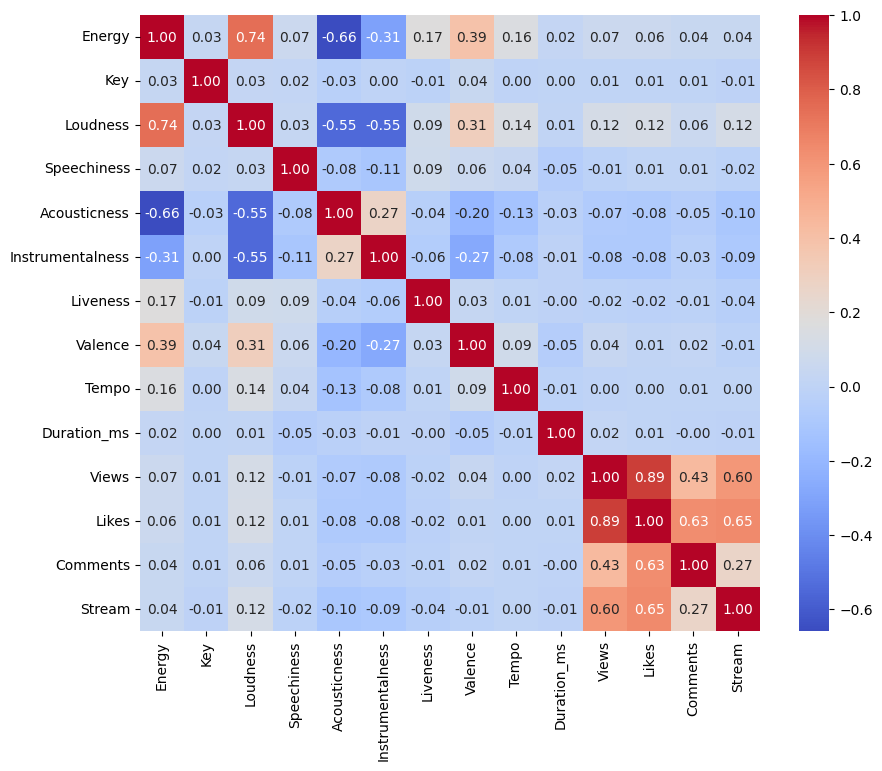

In [16]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [16]:
threshold = 0.8
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(np.bool_))
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > threshold)]

df = df.drop(to_drop, axis=1)
print("Dropped features:", to_drop)
df.head()

Dropped features: ['Likes']


,Track,Album_type,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Views,Comments,Stream
0,Feel Good Inc.,0,0.838974,0.704994,0.545455,0.838905,0.183610,0.008392,0.002330,0.607306,0.777442,0.569330,0.041260,0.085840,0.010564,0.307168
1,Rhinestone Eyes,0,0.693333,0.702994,0.727273,0.857222,0.031328,0.087248,0.000687,0.032268,0.858006,0.381149,0.036423,0.008913,0.001928,0.091562
2,New Gold (feat. Tame Impala and Bootie Brown),1,0.712821,0.922998,0.090909,0.897183,0.054149,0.042670,0.046900,0.102993,0.554884,0.443823,0.039647,0.001044,0.000460,0.018620
3,On Melancholy Hill,0,0.706667,0.738995,0.181818,0.857328,0.026971,0.000014,0.509000,0.050228,0.582075,0.494810,0.043677,0.026208,0.003434,0.128349
4,Clint Eastwood,0,0.680000,0.693994,0.909091,0.797609,0.177386,0.025401,0.000000,0.056114,0.528701,0.690108,0.066723,0.076548,0.009695,0.182268


### Why Use a Combined Engagement Score?

The **Score** combines **Views** (80%) and **Streams** (20%) to better reflect a track’s overall popularity across platforms. Views show immediate reach, while streams capture ongoing listener interest. This combined metric provides a more balanced and reliable target for prediction than using either alone, following industry practices.


In [17]:
def calculate_score(row):
    return (row['Views'] * 0.8 + (row['Stream'] * 0.2))

df['Score'] = df.apply(calculate_score, axis=1)
df = df.drop(["Views","Stream"], axis=1)
print(df)

                                               Track  Album_type  \
0                                     Feel Good Inc.           0   
1                                    Rhinestone Eyes           0   
2      New Gold (feat. Tame Impala and Bootie Brown)           1   
3                                 On Melancholy Hill           0   
4                                     Clint Eastwood           0   
...                                              ...         ...   
20713                           JUST DANCE HARDSTYLE           1   
20714                 SET FIRE TO THE RAIN HARDSTYLE           1   
20715                      OUTSIDE HARDSTYLE SPED UP           1   
20716                            ONLY GIRL HARDSTYLE           1   
20717                             MISS YOU HARDSTYLE           1   

       Danceability    Energy       Key  Loudness  Speechiness  Acousticness  \
0          0.838974  0.704994  0.545455  0.838905     0.183610      0.008392   
1          0.693333  0.

In [18]:
df = df.drop("Track", axis=1)
X = df.drop('Score',axis=1)
y = df['Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Check the shape of the datasets to verify the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
X.head()

X_train shape: (16574, 13)
X_test shape: (4144, 13)
y_train shape: (16574,)
y_test shape: (4144,)


,Album_type,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Comments
0,0,0.838974,0.704994,0.545455,0.838905,0.183610,0.008392,0.002330,0.607306,0.777442,0.569330,0.041260,0.010564
1,0,0.693333,0.702994,0.727273,0.857222,0.031328,0.087248,0.000687,0.032268,0.858006,0.381149,0.036423,0.001928
2,1,0.712821,0.922998,0.090909,0.897183,0.054149,0.042670,0.046900,0.102993,0.554884,0.443823,0.039647,0.000460
3,0,0.706667,0.738995,0.181818,0.857328,0.026971,0.000014,0.509000,0.050228,0.582075,0.494810,0.043677,0.003434
4,0,0.680000,0.693994,0.909091,0.797609,0.177386,0.025401,0.000000,0.056114,0.528701,0.690108,0.066723,0.009695


### Reshaping the data for model input

- `print(X_train.shape)` shows the data has 16,574 samples and 13 features.
- `reshape(16574, 13)` ensures the data is a 2D NumPy array with shape `(samples, features)`.
- This format is required for neural network input.


In [20]:
print(X_train.shape)
print(X_test.shape)

(16574, 13)
(4144, 13)


In [21]:
X_train = np.array(X_train).reshape(16574, 13)
X_test = np.array(X_test).reshape(4144, 13)

In [ ]:
model = Sequential(
    [
        Dense(1000, activation="relu", input_dim=13, name="layer1"),
        Dense(1000, activation="relu", name="layer2"),
        Dense(1000, activation="relu", name="layer3"),
        Dense(1000, activation="relu", name="layer4"),
        Dense(1000, activation="relu", name="layer5"),
        Dense(1, activation=None)
    ]
)

model.summary()

c:\Users\Jave\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 1000)           │        14,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer4 (Dense)                  │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer5 (Dense)                  │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,019,001 (15.33 MB)

 Trainable params: 4,019,001 (15.33 MB)

 Non-trainable params: 0 (0.00 B)

### Just checked if same datatype, nag error kasi

In [23]:
print(type(X_train), X_train.dtype)
print(type(y_train), y_train.dtype)
print(type(X_test), X_test.dtype)
print(type(y_test), y_test.dtype)


<class 'numpy.ndarray'> float64
<class 'pandas.core.series.Series'> float64
<class 'numpy.ndarray'> float64
<class 'pandas.core.series.Series'> float64


In [24]:
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error', metrics=['mae'])

history = model.fit(
    X_train, 
    y_train,
    epochs=50,
    validation_data=(X_test,y_test)
)

Epoch 1/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - loss: 0.0041 - mae: 0.0253 - val_loss: 0.0013 - val_mae: 0.0162
Epoch 2/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - loss: 0.0013 - mae: 0.0184 - val_loss: 0.0014 - val_mae: 0.0235
Epoch 3/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - loss: 0.0013 - mae: 0.0183 - val_loss: 0.0012 - val_mae: 0.0151
Epoch 4/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - loss: 0.0014 - mae: 0.0192 - val_loss: 0.0014 - val_mae: 0.0150
Epoch 5/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - loss: 0.0012 - mae: 0.0186 - val_loss: 0.0013 - val_mae: 0.0181
Epoch 6/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 0.0012 - mae: 0.0186 - val_loss: 0.0010 - val_mae: 0.0141
Epoch 7/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - loss: 0.0012 - mae: 0.0178 - val_loss: 8.4708e-04 - val_mae: 0.0151
Epoch 8/50
518/518 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 9.4529e-04 - mae: 0.0158 - val_loss: 9.6500e-04 - val_mae: 0.0134
Epoch 9/50
518/518 ━━━━━━━━━

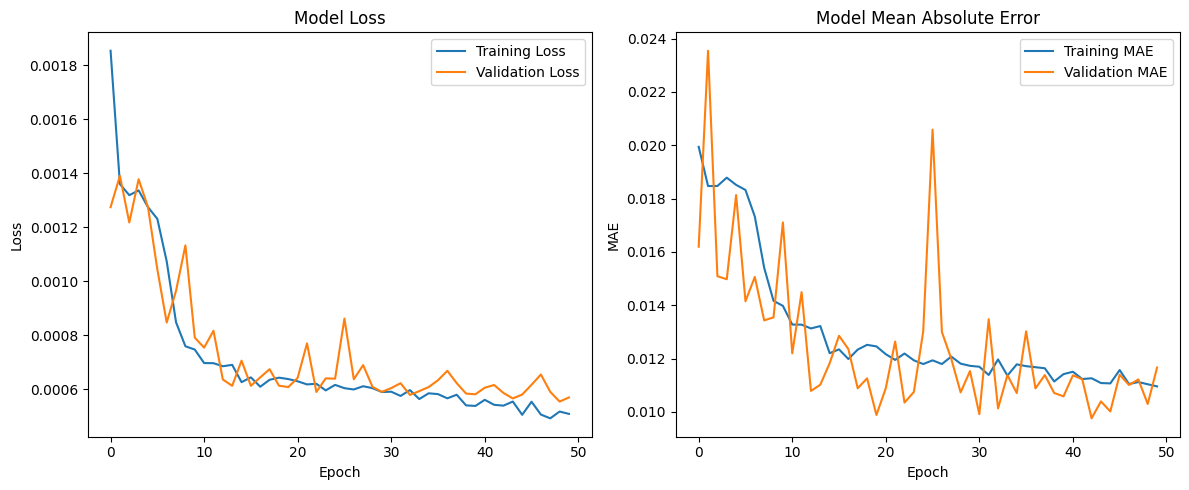

In [25]:
import matplotlib.pyplot as plt

# Plot training & validation loss and MAE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot loss
ax1.plot(history.history['loss'], label='Training Loss')
ax1.plot(history.history['val_loss'], label='Validation Loss')
ax1.set_title('Model Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend(loc='upper right')

# Plot MAE
ax2.plot(history.history['mae'], label='Training MAE')
ax2.plot(history.history['val_mae'], label='Validation MAE')
ax2.set_title('Model Mean Absolute Error')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MAE')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [26]:
y_pred = model.predict(X_test)


130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
explained_var = explained_variance_score(y_test, y_pred)

print(f"Test MSE: {mse:.6f}")
print(f"Test MAE: {mae:.6f}")
print(f"Test R²: {r2:.6f}")
print(f"Explained Variance: {explained_var:.6f}")


Test MSE: 0.000570
Test MAE: 0.011665
Test R²: 0.584316
Explained Variance: 0.595103


In [28]:
model.save("my_model.h5")

In [29]:
print("Min Score:", df['Score'].min())
print("Max Score:", df['Score'].max())
print("Mean Score:", df['Score'].mean())
print("Median Score:", df['Score'].median())


Min Score: 4.4160332214179076e-08
Max Score: 0.8889759688125096
Mean Score: 0.017329234455135446
Median Score: 0.006129027562172332


# Engagement Score Prediction
### Used my_model.h5 to predict song scores from Spotify_Youtube.csv.

- Cleaned, normalized, and engineered features

- Used saved model (`my_model.h5`) to avoid retraining

Output: comparison table + scatter plot (actual vs predicted)

C:\Users\Jave\AppData\Local\Temp\ipykernel_29240\2655670386.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
C:\Users\Jave\AppData\Local\Temp\ipykernel_29240\2655670386.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example

130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
      Song ID  Actual Score  Predicted Score
149       150      0.001293         0.008347
296       297      0.000524         0.008430
1582     1583      0.002838         0.008287
1610     1611      0.001014         0.006011
1644     1645      0.161280         0.090479
1966     1967      0.003109         0.007878
2351     2352      0.003118         0.008741
2567     2568      0.002799         0.008153


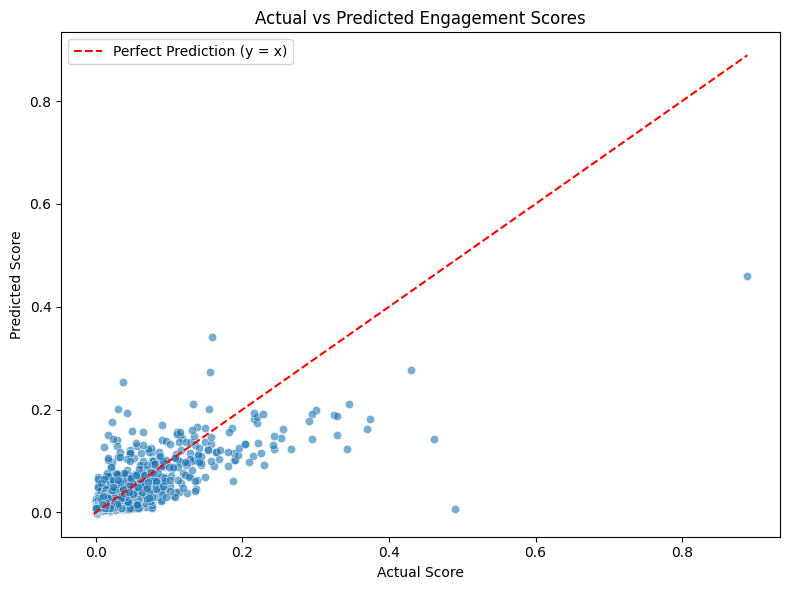

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_csv('Spotify_Youtube.csv')

# Drop irrelevant columns
columns_to_delete = ['Unnamed: 0', 'Url_spotify', 'Uri', 'Url_youtube', 'Title', 'Channel',
                     'Description', 'Licensed', 'official_video', "Artist", "Album"]
df = df.drop(columns=columns_to_delete)

# Fill missing values
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(exclude=['number']).columns

for col in num_cols:
    df[col].fillna(df[col].mean(), inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Factorize categorical column
df['Album_type'], _ = pd.factorize(df['Album_type'])

# Normalize numerical columns
scaler = MinMaxScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df['Loudness'] = scaler.fit_transform(df[['Loudness']])  # Redundant but kept for safety

# Drop highly correlated features
correlation_matrix = df.iloc[:, 3:].corr()
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_triangle.columns if any(upper_triangle[col] > 0.8)]
df = df.drop(to_drop, axis=1)

# Create score and drop original components
df['Score'] = df['Views'] * 0.8 + df['Stream'] * 0.2
df.drop(['Views', 'Stream'], axis=1, inplace=True)

# Drop track name
df.drop('Track', axis=1, inplace=True)

# Split into X and y
X = df.drop('Score', axis=1)
y = df['Score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Reshape
X_test = np.array(X_test).reshape(X_test.shape[0], X_test.shape[1])

# Load the saved model
model = load_model("my_model.h5")

# Predict
y_pred = model.predict(X_test)

# Create DataFrame for comparison
results_df = pd.DataFrame({
    'Song ID': range(1, len(y_test)+1),
    'Actual Score': y_test.reset_index(drop=True),
    'Predicted Score': y_pred.flatten()
})

# Show sample table
sample_df = results_df.sample(8, random_state=42).sort_values('Song ID')
print(sample_df)

# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Actual Score', y='Predicted Score', data=results_df, alpha=0.6)
lims = [
    results_df[['Actual Score', 'Predicted Score']].min().min(),
    results_df[['Actual Score', 'Predicted Score']].max().max()
]
plt.plot(lims, lims, 'r--', label='Perfect Prediction (y = x)')
plt.xlabel('Actual Score')
plt.ylabel('Predicted Score')
plt.title('Actual vs Predicted Engagement Scores')
plt.legend()
plt.tight_layout()
plt.show()


### Command-Line Interface for Song Engagement Score Prediction

This code implements a simple command-line interface (CLI) that allows users to input a song name and receive both the actual and predicted engagement scores for that song.

- The dataset is preprocessed similarly as before, but the `Track` (song name) column is retained to allow song lookup.
- When a user inputs a song name, the program searches the dataset for an exact (case-insensitive) match.
- If found, it extracts the features for that song, uses a pre-trained Multilayer Perceptron (MLP) model to predict the engagement score, and displays both actual and predicted scores.
- The CLI continues accepting inputs until the user types "exit" to quit.

This interface provides an interactive way to quickly evaluate the model's predictions on specific songs from the dataset.


In [9]:
# Load original dataset (without dropping 'Track' column)
df = pd.read_csv('Spotify_Youtube.csv')

# Save track names before dropping columns
track_names = df['Track']

# Drop irrelevant columns except 'Track'
columns_to_delete = ['Unnamed: 0', 'Url_spotify', 'Uri', 'Url_youtube', 'Title', 'Channel',
                     'Description', 'Licensed', 'official_video', "Artist", "Album"]
df = df.drop(columns=columns_to_delete)

# Fill missing values (same as before)
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(exclude=['number']).columns

for col in num_cols:
    df[col].fillna(df[col].mean(), inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

df['Album_type'], _ = pd.factorize(df['Album_type'])

# Normalize numerical columns
scaler = MinMaxScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df['Loudness'] = scaler.fit_transform(df[['Loudness']])

# Drop highly correlated features (same as before)
correlation_matrix = df.iloc[:, 3:].corr()
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_triangle.columns if any(upper_triangle[col] > 0.8)]
df = df.drop(to_drop, axis=1)

# Create score and drop original components
df['Score'] = df['Views'] * 0.8 + df['Stream'] * 0.2
df.drop(['Views', 'Stream'], axis=1, inplace=True)

# Don't drop 'Track' here, keep it
# df.drop('Track', axis=1, inplace=True) 

# Load model
model = load_model("my_model.h5")

def predict_song_score(song_name):
    # Find the row with the matching song name (case insensitive)
    mask = df['Track'].str.lower() == song_name.lower()
    
    if not mask.any():
        print(f"Song '{song_name}' not found in dataset.")
        return
    
    song_data = df[mask]
    actual_score = song_data['Score'].values[0]
    
    # Prepare features for prediction (drop 'Score' and 'Track')
    X = song_data.drop(['Score', 'Track'], axis=1)
    
    # Predict
    pred_score = model.predict(X)
    
    print(f"Song: {song_name}")
    print(f"Actual Engagement Score: {actual_score:.4f}")
    print(f"Predicted Engagement Score: {pred_score[0][0]:.4f}")

if __name__ == "__main__":
    while True:
        song_input = input("Enter song name (or 'exit' to quit): ").strip()
        if song_input.lower() == 'exit':
            break
        predict_song_score(song_input)


C:\Users\Jave\AppData\Local\Temp\ipykernel_14412\3793230133.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
C:\Users\Jave\AppData\Local\Temp\ipykernel_14412\3793230133.py:20: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Song: Take on me
Actual Engagement Score: 0.2354
Predicted Engagement Score: 0.1552
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Song: In the end
Actual Engagement Score: 0.2326
Predicted Engagement Score: 0.1408
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Song: Believer
Actual Engagement Score: 0.3746
Predicted Engagement Score: 0.1819
Song 'Thriller' not found in dataset.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Song: Bad guy
Actual Engagement Score: 0.2514
Predicted Engagement Score: 0.2176
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Song: Shape of you
Actual Engagement Score: 0.7836
Predicted Engagement Score: 0.3510
Song 'Bad blood' not found in dataset.


### Example Predictions from the Command-Line Interface

The interactive CLI was used to predict engagement scores for several popular songs. Table 3 summarizes a selection of results comparing actual and predicted scores:

| Song           | Actual Engagement Score | Predicted Engagement Score |
|----------------|------------------------|----------------------------|
| Take on Me     | 0.2354                 | 0.1552                     |
| In the End     | 0.2326                 | 0.1408                     |
| Believer       | 0.3746                 | 0.1819                     |
| Bad Guy        | 0.2514                 | 0.2176                     |
| Shape of You   | 0.7836                 | 0.3510                     |

